# Project Name- Mutual Fund Overview & Insights

## Project Summary
The main goal of this project is to perform a Mutual Fund Overview & Insights analysis on the comprehensive_mutual_funds_data dataset to identify High-Return, Low-Risk fund schemes and shortlist the Top 30 funds. This project directly benefits everyday investors by helping them make smarter financial decisions. The final outputs, including the Top 30 fund shortlist and an interactive Power BI dashboard, help non-technical investors easily to understand risk, costs, and performance trade-offs through actionable, meaningful insights without getting lost in confusing financial terms.

### Steps:

**Data Collection & Cleaning:** This project uses datasets containing expense ratio, risk level, fund age, AMC, and category in mutual_fund_schemes.The data was cleaned by handling missing values, removing duplicate values & data consistency.

**Data visualisation**: Various visualisation techniques are used to find patterns and relationships in the data.

**Charts & Insights**: Various charts & insights are used to analyse the risk and help everyday investors to make better decisions.




# Import Libraries

In [6]:
import numpy as np
import pandas as pd
from sklearn. preprocessing import  MinMaxScaler
from sklearn.model_selection import train_test_split

# Data Preprocessing

In [7]:
#load datasets
df=pd.read_csv('comprehensive_mutual_funds_data.csv')
df

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,returns_5yr
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,returns_5yr
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,returns_5yr
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809,UTI-Unit Linked Insurance Plan – Direct,500,15000,0.96,5068.0,10,Amandeep Chopra,2.47,0.92,7.06,0.44,1.29,4,UTI Mutual Fund,0,Hybrid,Dynamic Asset Allocation or Balanced Advantage,-0.7,13.1,6.2
810,UTI-Value Opportunities Fund,500,5000,1.16,6740.0,10,Vetri Subramaniam,3.21,2.73,15.62,0.9,1.48,6,UTI Mutual Fund,4,Equity,Value Funds,1.7,27.2,12.2
811,WhiteOak Capital Liquid Fund,500,500,0.26,197.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Liquid Mutual Funds,5.3,3.8,NaN
812,WhiteOak Capital Overnight Fund,500,500,0.22,14.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Overnight Mutual Funds,1.7,32.4,13.3


In [8]:
df.shape

(814, 20)

In [9]:
df.columns

Index(['scheme_name', 'min_sip', 'min_lumpsum', 'expense_ratio',
       'fund_size_cr', 'fund_age_yr', 'fund_manager', 'sortino', 'alpha', 'sd',
       'beta', 'sharpe', 'risk_level', 'amc_name', 'rating', 'category',
       'sub_category', 'returns_1yr', 'returns_3yr', 'returns_5yr'],
      dtype='object')

In [10]:
df.isnull().sum()

scheme_name        0
min_sip            0
min_lumpsum        0
expense_ratio      0
fund_size_cr       0
fund_age_yr        0
fund_manager       0
sortino            0
alpha              0
sd                 0
beta               0
sharpe             0
risk_level         0
amc_name           0
rating             0
category           0
sub_category       0
returns_1yr        0
returns_3yr       21
returns_5yr      167
dtype: int64

In [11]:
df['returns_3yr']=df['returns_3yr'].fillna(df['returns_3yr'].median())
#drop duplicate valuesin  the  returns_5yr
df=df[df['returns_5yr']!='returns_5yr']
#convert to numeric
df['returns_5yr']=pd.to_numeric(df['returns_5yr'],errors='coerce')

C:\Users\DELL\AppData\Local\Temp\ipykernel_16240\822778716.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['returns_5yr']=pd.to_numeric(df['returns_5yr'],errors='coerce')


In [12]:
df.dtypes

scheme_name       object
min_sip            int64
min_lumpsum        int64
expense_ratio    float64
fund_size_cr     float64
fund_age_yr        int64
fund_manager      object
sortino           object
alpha             object
sd                object
beta              object
sharpe            object
risk_level         int64
amc_name          object
rating             int64
category          object
sub_category      object
returns_1yr      float64
returns_3yr      float64
returns_5yr      float64
dtype: object

In [13]:
df['returns_5yr']=df['returns_5yr'].fillna(df['returns_5yr'].median())

C:\Users\DELL\AppData\Local\Temp\ipykernel_16240\1812632315.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['returns_5yr']=df['returns_5yr'].fillna(df['returns_5yr'].median())


In [14]:
df.isnull().sum()


scheme_name      0
min_sip          0
min_lumpsum      0
expense_ratio    0
fund_size_cr     0
fund_age_yr      0
fund_manager     0
sortino          0
alpha            0
sd               0
beta             0
sharpe           0
risk_level       0
amc_name         0
rating           0
category         0
sub_category     0
returns_1yr      0
returns_3yr      0
returns_5yr      0
dtype: int64

In [15]:
df=df.drop_duplicates()

In [16]:
df

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,8.9
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7
5,Aditya Birla SL Banking&Financial Services-Dir...,1000,1000,1.17,2384.0,9,Dhaval Gala,2.07,1.24,25.53,0.96,0.97,6,Aditya Birla Sun Life Mutual Fund,2,Equity,Sectoral / Thematic Mutual Funds,5.3,24.6,9.2
6,Aditya Birla SL Banking&PSU Debt Fund,1000,1000,0.37,7994.0,10,Kaustubh Gupta,1.92,4.46,1.91,1.78,1.09,3,Aditya Birla Sun Life Mutual Fund,4,Debt,Banking and PSU Mutual Funds,4.5,6.8,7.3
7,Aditya Birla SL CEF – Global Agri Plan-Direct ...,1000,1000,1.29,15.0,10,Vinod Narayan Bhat,1.42,-,20.18,-,1.06,6,Aditya Birla Sun Life Mutual Fund,0,Equity,Sectoral / Thematic Mutual Funds,-10.3,29.4,9.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809,UTI-Unit Linked Insurance Plan – Direct,500,15000,0.96,5068.0,10,Amandeep Chopra,2.47,0.92,7.06,0.44,1.29,4,UTI Mutual Fund,0,Hybrid,Dynamic Asset Allocation or Balanced Advantage,-0.7,13.1,6.2
810,UTI-Value Opportunities Fund,500,5000,1.16,6740.0,10,Vetri Subramaniam,3.21,2.73,15.62,0.9,1.48,6,UTI Mutual Fund,4,Equity,Value Funds,1.7,27.2,12.2
811,WhiteOak Capital Liquid Fund,500,500,0.26,197.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Liquid Mutual Funds,5.3,3.8,8.9
812,WhiteOak Capital Overnight Fund,500,500,0.22,14.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Overnight Mutual Funds,1.7,32.4,13.3


In [17]:
df.describe()

,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,risk_level,rating,returns_1yr,returns_3yr,returns_5yr
count,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000,811.000000
mean,527.865598,3056.151665,0.714439,3821.465265,8.313194,4.405672,2.639951,3.921578,18.555980,9.376942
std,368.817038,2515.070406,0.482598,7192.353837,2.643522,1.813371,1.466021,6.687251,11.955956,3.321453
min,0.000000,0.000000,0.000000,2.380000,1.000000,1.000000,0.000000,-19.700000,3.300000,-4.100000
25%,150.000000,500.000000,0.310000,177.000000,6.000000,3.000000,2.000000,1.500000,6.300000,7.100000
50%,500.000000,5000.000000,0.620000,946.000000,10.000000,6.000000,3.000000,4.400000,18.500000,8.900000
75%,1000.000000,5000.000000,1.030000,3812.000000,10.000000,6.000000,4.000000,5.600000,27.000000,11.500000
max,2000.000000,25000.000000,2.590000,57052.000000,17.000000,6.000000,5.000000,130.800000,71.400000,23.200000


# Data Visualisation

Data Visualisation is the graphical representation of the information and data.By using visuals like charts,graphs and maps. data visualisation tools help to  understand the trends,patterns and outliers in the data.

## Univariate Analysis

In [18]:
df

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,8.9
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7
5,Aditya Birla SL Banking&Financial Services-Dir...,1000,1000,1.17,2384.0,9,Dhaval Gala,2.07,1.24,25.53,0.96,0.97,6,Aditya Birla Sun Life Mutual Fund,2,Equity,Sectoral / Thematic Mutual Funds,5.3,24.6,9.2
6,Aditya Birla SL Banking&PSU Debt Fund,1000,1000,0.37,7994.0,10,Kaustubh Gupta,1.92,4.46,1.91,1.78,1.09,3,Aditya Birla Sun Life Mutual Fund,4,Debt,Banking and PSU Mutual Funds,4.5,6.8,7.3
7,Aditya Birla SL CEF – Global Agri Plan-Direct ...,1000,1000,1.29,15.0,10,Vinod Narayan Bhat,1.42,-,20.18,-,1.06,6,Aditya Birla Sun Life Mutual Fund,0,Equity,Sectoral / Thematic Mutual Funds,-10.3,29.4,9.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
809,UTI-Unit Linked Insurance Plan – Direct,500,15000,0.96,5068.0,10,Amandeep Chopra,2.47,0.92,7.06,0.44,1.29,4,UTI Mutual Fund,0,Hybrid,Dynamic Asset Allocation or Balanced Advantage,-0.7,13.1,6.2
810,UTI-Value Opportunities Fund,500,5000,1.16,6740.0,10,Vetri Subramaniam,3.21,2.73,15.62,0.9,1.48,6,UTI Mutual Fund,4,Equity,Value Funds,1.7,27.2,12.2
811,WhiteOak Capital Liquid Fund,500,500,0.26,197.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Liquid Mutual Funds,5.3,3.8,8.9
812,WhiteOak Capital Overnight Fund,500,500,0.22,14.0,4,Piyush Baranwal,-0.42,0.93,0.39,0.72,-0.07,1,WhiteOak Capital Mutual Fund,1,Debt,Overnight Mutual Funds,1.7,32.4,13.3


## Box plot

### Box plot of return rates

Box plots are used to visualise the distribution and spread of the data and to identify the outliers in the data.

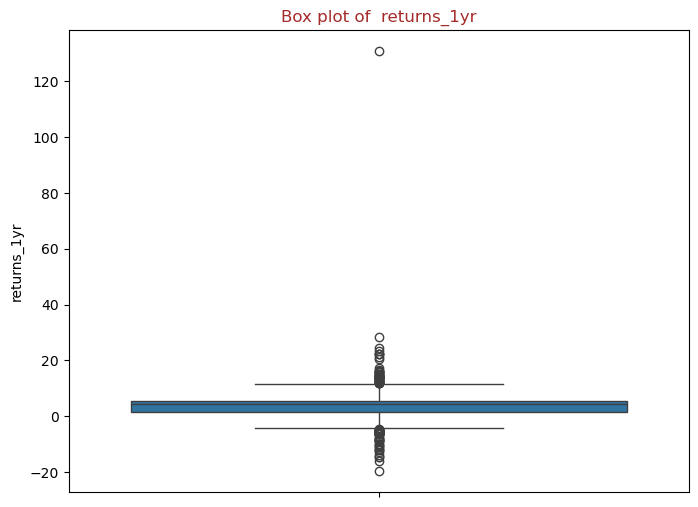

In [19]:
#box plot of return rates
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,6))
sns.boxplot(data=df,y='returns_1yr')
plt.title('Box plot of  returns_1yr',color='brown')
plt.show()


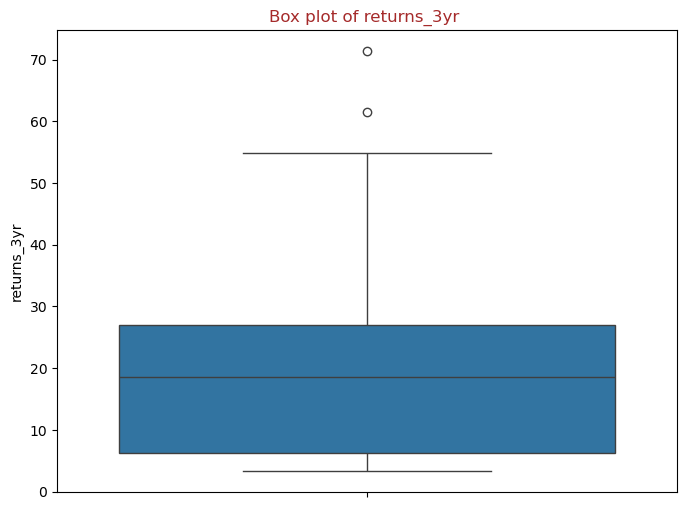

In [20]:
#box plot for returns_3yr
plt.figure(figsize=(8,6))
sns.boxplot(data=df,y='returns_3yr')
plt.title('Box plot of returns_3yr ',color='brown')
plt.show()

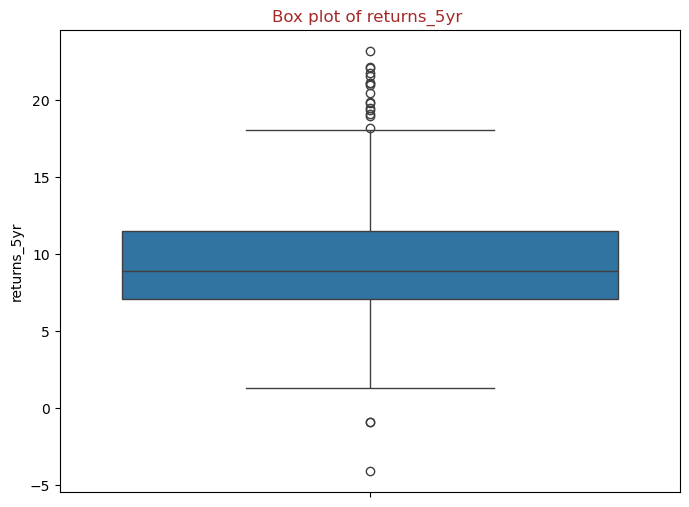

In [21]:
#box plot for returns_3yr
plt.figure(figsize=(8,6))
sns.boxplot(data=df,y='returns_5yr')
plt.title('Box plot of returns_5yr ',color='brown')
plt.show()

## Bar plot

 Bar plot is  the type  of charts that represents categorical data with rectangular bars with height or length propotional to that values.

#### Bar plot of Risk level


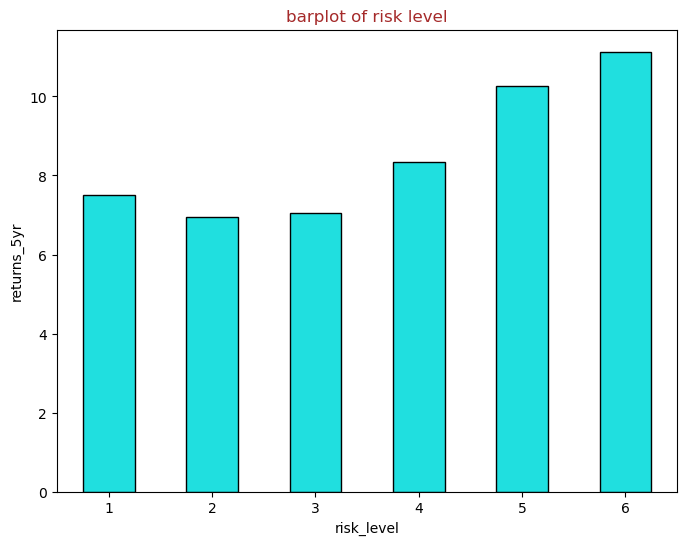

In [22]:
#bar plot ,risk-level across the return ratein 5yr
plt.figure(figsize=(8,6))
sns.barplot(data=df,x='risk_level',y='returns_5yr',width=0.5,color='cyan',edgecolor='black',errorbar=None)
plt.title('barplot of risk level',color='brown')
plt.xlabel('risk_level')
plt.ylabel('returns_5yr')
plt.show()

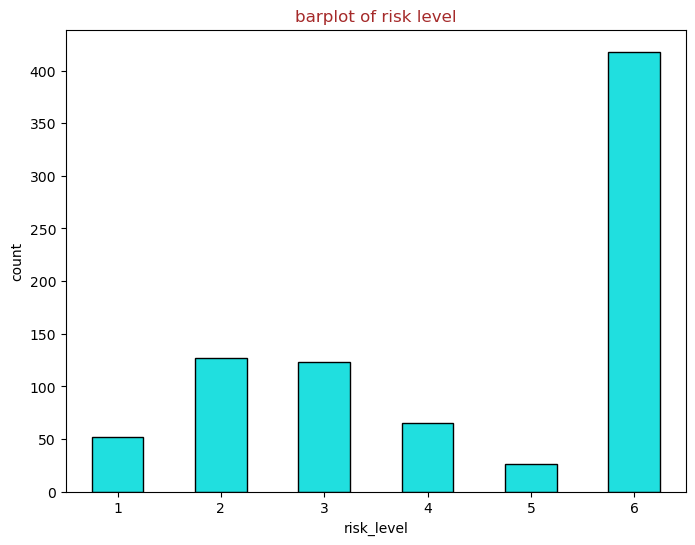

In [23]:
#bar plot, risklevel across funds
plt.figure(figsize=(8,6))
sns.countplot(data=df,x='risk_level',width=0.5,color='cyan',edgecolor='black')
plt.title('barplot of risk level',color='brown')
plt.xlabel('risk_level')
plt.show()

In [24]:
a=df.fund_age_yr.value_counts()
a

fund_age_yr
10    505
4      91
5      52
9      38
8      35
3      27
2      19
7      19
6      18
14      2
17      2
1       1
12      1
11      1
Name: count, dtype: int64

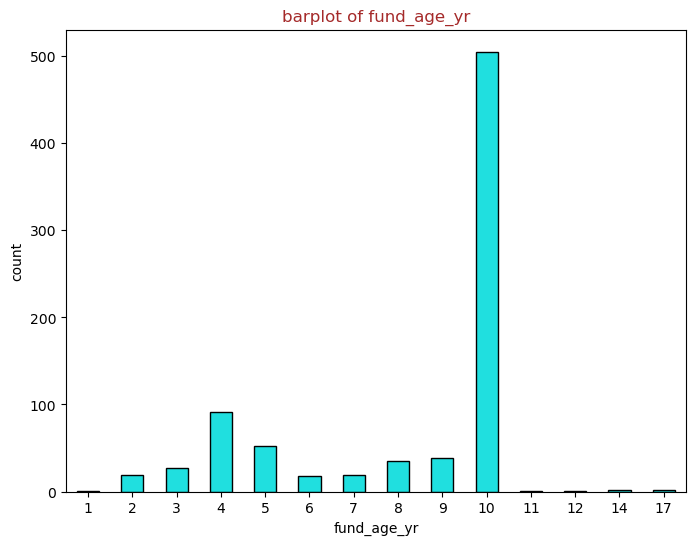

In [25]:
#bar plot, fund_age across funds
plt.figure(figsize=(8,6))
sns.barplot(x=a.index,y=a.values,width=0.5,color='cyan',edgecolor='black')
plt.title('barplot of fund_age_yr',color='brown')
plt.xlabel('fund_age_yr')
plt.ylabel('count')
plt.show()

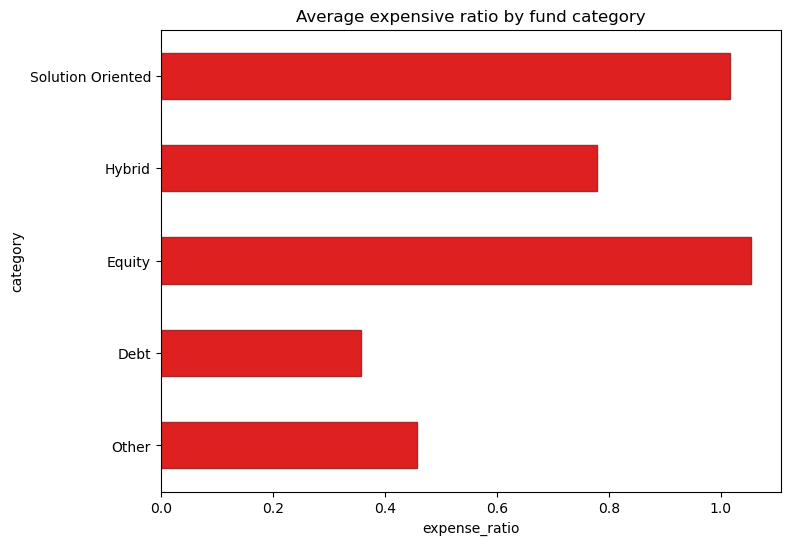

In [26]:
#Horizontal   bar chart of average expense ratio by fund category
plt.figure(figsize=(8,6))
sns.barplot(data=df,x='expense_ratio',y='category',width=0.5,edgecolor='brown',color='red',errorbar=None)
plt.title('Average expensive ratio by fund category')
plt.show()




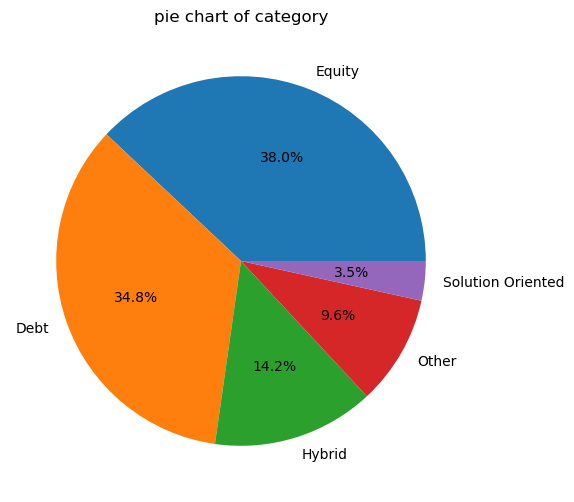

In [27]:
#pie chart
plt.figure(figsize=(8,6))
plt.pie(df['category'].value_counts(),labels=df['category'].value_counts().index,autopct='%1.1f%%')
plt.title('pie chart of category')
plt.show()

    


# Normalization

In [28]:
#df=df.drop(columns=['scheme_name','fund_manager'])

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 811 entries, 3 to 813
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    811 non-null    object 
 1   min_sip        811 non-null    int64  
 2   min_lumpsum    811 non-null    int64  
 3   expense_ratio  811 non-null    float64
 4   fund_size_cr   811 non-null    float64
 5   fund_age_yr    811 non-null    int64  
 6   fund_manager   811 non-null    object 
 7   sortino        811 non-null    object 
 8   alpha          811 non-null    object 
 9   sd             811 non-null    object 
 10  beta           811 non-null    object 
 11  sharpe         811 non-null    object 
 12  risk_level     811 non-null    int64  
 13  amc_name       811 non-null    object 
 14  rating         811 non-null    int64  
 15  category       811 non-null    object 
 16  sub_category   811 non-null    object 
 17  returns_1yr    811 non-null    float64
 18  returns_3yr    

### Dataset Description
The dataset is related to the mutual_fund schemes.**comprehensive_mutual_funds_data.csv**is the datasets which contains informations about funds.
## Columns in datasets
scheme_name: It represents the fund name.

amc_name: Company managing the fund

fund_size_cr: AUM

expense_ratio: Fund Fee

fund_age_yr: Fund Age

returns_1yr:1-year return

returns_3yr:3-Year Return

returns_5yr:5-Year Return

rating: Fund Rating

risk_level: Risk Category


In [30]:
metric_cols = ['sortino', 'alpha', 'sd', 'beta', 'sharpe']
df[metric_cols] = df[metric_cols].apply(pd.to_numeric, errors='coerce')
print(df[metric_cols].dtypes)

sortino    float64
alpha      float64
sd         float64
beta       float64
sharpe     float64
dtype: object


In [31]:

#df=df.drop(columns=['amc_name'])
df=df.drop(columns=['category','sub_category'])

In [32]:

df.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,returns_1yr,returns_3yr,returns_5yr
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.90,6,Aditya Birla Sun Life Mutual Fund,2,-0.7,17.1,8.9
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,4.5,18.6,9.7
5,Aditya Birla SL Banking&Financial Services-Dir...,1000,1000,1.17,2384.0,9,Dhaval Gala,2.07,1.24,25.53,0.96,0.97,6,Aditya Birla Sun Life Mutual Fund,2,5.3,24.6,9.2
6,Aditya Birla SL Banking&PSU Debt Fund,1000,1000,0.37,7994.0,10,Kaustubh Gupta,1.92,4.46,1.91,1.78,1.09,3,Aditya Birla Sun Life Mutual Fund,4,4.5,6.8,7.3
7,Aditya Birla SL CEF – Global Agri Plan-Direct ...,1000,1000,1.29,15.0,10,Vinod Narayan Bhat,1.42,NaN,20.18,NaN,1.06,6,Aditya Birla Sun Life Mutual Fund,0,-10.3,29.4,9.3


In [33]:
#df.isnull().sum()

In [34]:
#df['sortino']=df['sortino'].fillna(df['sortino'].median())
#df['alpha']=df['alpha'].fillna(df['alpha'].median())
#df['sd']=df['sd'].fillna(df['sd'].median())
#df['beta']=df['beta'].fillna(df['beta'].median())
#df['sharpe']=df['sharpe'].fillna(df['sharpe'].median())

In [35]:
#df.isnull().sum()

In [36]:
#numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
#print(numeric_cols)

In [37]:
#df.dtypes

In [38]:

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 811 entries, 3 to 813
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    811 non-null    object 
 1   min_sip        811 non-null    int64  
 2   min_lumpsum    811 non-null    int64  
 3   expense_ratio  811 non-null    float64
 4   fund_size_cr   811 non-null    float64
 5   fund_age_yr    811 non-null    int64  
 6   fund_manager   811 non-null    object 
 7   sortino        788 non-null    float64
 8   alpha          769 non-null    float64
 9   sd             787 non-null    float64
 10  beta           769 non-null    float64
 11  sharpe         788 non-null    float64
 12  risk_level     811 non-null    int64  
 13  amc_name       811 non-null    object 
 14  rating         811 non-null    int64  
 15  returns_1yr    811 non-null    float64
 16  returns_3yr    811 non-null    float64
 17  returns_5yr    811 non-null    float64
dtypes: float64(10),

In [39]:
X2=df.iloc[:,0:15]


In [40]:
df.columns

Index(['scheme_name', 'min_sip', 'min_lumpsum', 'expense_ratio',
       'fund_size_cr', 'fund_age_yr', 'fund_manager', 'sortino', 'alpha', 'sd',
       'beta', 'sharpe', 'risk_level', 'amc_name', 'rating', 'returns_1yr',
       'returns_3yr', 'returns_5yr'],
      dtype='object')

In [41]:
#X2.isnull().sum()

In [42]:
#X2 = X2.fillna(X2.median())


In [43]:
##scaleMinMax=MinMaxScaler(feature_range=(0,1))
#X2=scaleMinMax.fit_transform(X2)
#X2=pd.DataFrame(X2,columns=['min_sip', 'min_lumpsum', 'expense_ratio', 'fund_size_cr', 'fund_age_yr', 'sortino', 'alpha', 'sd', 'beta', 'sharpe', 'risk_level', 'rating', 'returns_1yr', 'returns_3yr', 'returns_5yr'])
#X2.head()

In [44]:

numeric_cols = X2.select_dtypes(include=['number']).columns

# Scale only those numeric columns
scaleMinMax = MinMaxScaler(feature_range=(0, 1))
X2[numeric_cols] = scaleMinMax.fit_transform(X2[numeric_cols])

X2.head()

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,0.25,0.040,0.293436,0.011124,0.1875,Atul Penkar,0.275453,0.172167,0.190058,0.877885,0.396313,1.0,Aditya Birla Sun Life Mutual Fund,0.4
4,Aditya Birla SL Balanced Advantage Fund,0.05,0.004,0.235521,0.111896,0.5625,Mohit Sharma,0.380753,0.378079,0.130536,0.873323,0.509217,1.0,Aditya Birla Sun Life Mutual Fund,0.8
5,Aditya Birla SL Banking&Financial Services-Dir...,0.50,0.040,0.451737,0.041746,0.5000,Dhaval Gala,0.267782,0.359606,0.326146,0.880837,0.412442,1.0,Aditya Birla Sun Life Mutual Fund,0.4
6,Aditya Birla SL Banking&PSU Debt Fund,0.50,0.040,0.142857,0.140082,0.5625,Kaustubh Gupta,0.257322,0.438916,0.021175,0.902845,0.440092,0.4,Aditya Birla Sun Life Mutual Fund,0.8
7,Aditya Birla SL CEF – Global Agri Plan-Direct ...,0.50,0.040,0.498069,0.000221,0.5625,Vinod Narayan Bhat,0.222455,NaN,0.257069,NaN,0.433180,1.0,Aditya Birla Sun Life Mutual Fund,0.0


In [45]:
X2.describe().round(3)

,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,sortino,alpha,sd,beta,sharpe,risk_level,rating
count,811.000,811.000,811.000,811.000,811.000,788.000,769.000,787.000,769.000,788.000,811.000,811.000
mean,0.264,0.122,0.276,0.067,0.457,0.309,0.391,0.129,0.877,0.467,0.681,0.528
std,0.184,0.101,0.186,0.126,0.165,0.097,0.098,0.101,0.035,0.124,0.363,0.293
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.075,0.020,0.120,0.003,0.312,0.247,0.342,0.024,0.874,0.403,0.400,0.400
50%,0.250,0.200,0.239,0.017,0.562,0.324,0.374,0.156,0.878,0.487,1.000,0.600
75%,0.500,0.200,0.398,0.067,0.562,0.366,0.424,0.209,0.881,0.546,1.000,0.800
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


# Fund Score and Fund Ranking

In [68]:
import numpy as np
import pandas as pd


df = pd.read_csv('comprehensive_mutual_funds_data.csv')


# df_raw = pd.read_csv('comprehensive_mutual_funds_data.csv')
# df['scheme_name'] = df_raw.loc[df.index, 'scheme_name']


# 2. Min-Max Normalization  Functions
def normalize_positive(series):
  return (series - series.min()) / (series.max() - series.min()) * 100


def normalize_negative(series):
  return (series.max() - series) / (series.max() - series.min()) * 100


# 3. Calculate Component Scores
df['score_3yr'] = normalize_positive(df['returns_3yr'])
df['score_1yr'] = normalize_positive(df['returns_1yr'])
df['score_age'] = normalize_positive(df['fund_age_yr'])
df['score_exp'] = normalize_negative(df['expense_ratio'])

# 4. Calculate Final Fund Score
df['fund_score'] = (
    (df['score_3yr'] * 0.40)
    + (df['score_exp'] * 0.30)
    + (df['score_age'] * 0.20)
    + (df['score_1yr'] * 0.10)
).round(2)

# 5. Handle missing/NaN values in fund_score (fill with 0 or drop rows)

df['fund_score'] = df['fund_score'].fillna(0)

# 6. Compute Fund Ranking safely
df['fund_rank'] = df['fund_score'].rank(ascending=False, method='min').astype(int)

# 7. Sort by Rank
df_sorted = df.sort_values(by='fund_rank', ascending=True)



In [69]:
rank_list = df_sorted[['fund_rank', 'scheme_name', 'fund_score']].head()
display(rank_list)

,fund_rank,scheme_name,fund_score
608,1,Quant Small Cap Fund,75.50
603,2,Quant Infrastructure Fund,69.70
609,3,Quant Tax Plan- Direct Growth,66.32
601,4,Quant Flexi Cap Fund,62.37
600,5,Quant Active Fund,60.69


In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 26 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   scheme_name    814 non-null    object 
 1   min_sip        814 non-null    int64  
 2   min_lumpsum    814 non-null    int64  
 3   expense_ratio  814 non-null    float64
 4   fund_size_cr   814 non-null    float64
 5   fund_age_yr    814 non-null    int64  
 6   fund_manager   814 non-null    object 
 7   sortino        814 non-null    object 
 8   alpha          814 non-null    object 
 9   sd             814 non-null    object 
 10  beta           814 non-null    object 
 11  sharpe         814 non-null    object 
 12  risk_level     814 non-null    int64  
 13  amc_name       814 non-null    object 
 14  rating         814 non-null    int64  
 15  category       814 non-null    object 
 16  sub_category   814 non-null    object 
 17  returns_1yr    814 non-null    float64
 18  returns_3y

In [74]:
# 8. Display top results or extract top 30
top_30_funds = df_sorted.head(30)
display(
    top_30_funds[[
        'fund_rank',
        'scheme_name' if 'scheme_name' in df.columns else df.columns[0],
        'fund_score',
    ]]
)

# 9. Export to Excel/CSV
top_30_funds.to_excel('Top_30_Mutual_Funds.xlsx', index=False)
print(' Top 30 Funds exported successfully')

,fund_rank,scheme_name,fund_score
608,1,Quant Small Cap Fund,75.50
603,2,Quant Infrastructure Fund,69.70
609,3,Quant Tax Plan- Direct Growth,66.32
601,4,Quant Flexi Cap Fund,62.37
600,5,Quant Active Fund,60.69
606,6,Quant Mid Cap Fund,60.40
607,7,Quant Multi Asset Fund,59.86
594,8,PGIM India Midcap Opportunities Fund,59.37
571,9,Nippon India Small Cap Fund,59.20
459,10,Kotak Small Cap Fund,59.06


 Top 30 Funds exported successfully


In [75]:
top_30_funds.to_csv('Top_30_Mutual_Funds.csv', index=False)
print(' Top 30 Funds successfully exported to Top_30_Mutual_Funds1.csv')

 Top 30 Funds successfully exported to Top_30_Mutual_Funds1.csv
